# Net Promoter Score with uncertainty
NPS = % promoters (9-10) − % detractors (0-6). Small monthly samples make NPS noisy, so a **bootstrap confidence interval** separates real changes from noise before management reacts.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
n = pd.read_csv("data/nps_responses.csv", parse_dates=["event_date"])
n["group"] = pd.cut(n.score, [-1, 6, 8, 10], labels=["detractor", "passive", "promoter"])
nps = lambda x: ((x >= 9).mean() - (x <= 6).mean()) * 100
print(f"{len(n):,} responses, overall NPS = {nps(n.score):.1f}")
n.group.value_counts(normalize=True).round(3)

3,326 responses, overall NPS = 50.4


group
promoter     0.615
passive      0.274
detractor    0.111
Name: proportion, dtype: float64

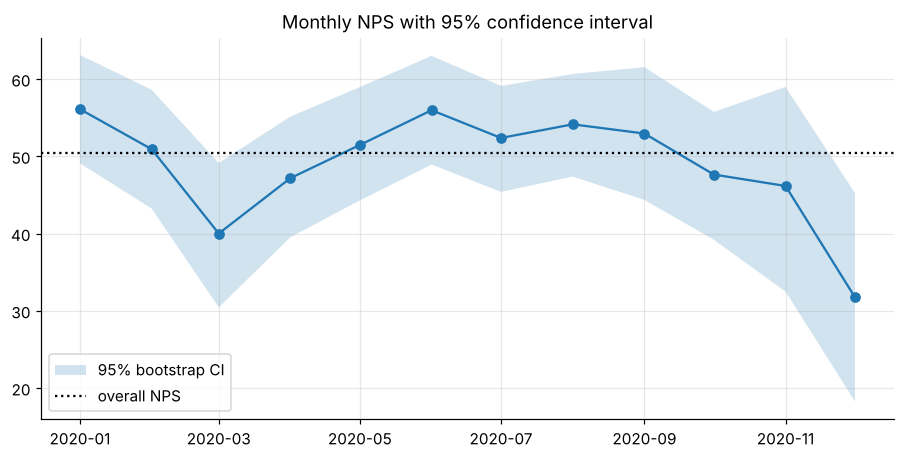

,n,NPS,lo,hi
event_date,,,,
2020-01-01,328,56.1,49.1,63.1
2020-02-01,273,50.9,43.2,58.6
2020-03-01,230,40.0,30.4,49.1
2020-04-01,301,47.2,39.5,55.1
2020-05-01,307,51.5,44.3,59.0
2020-06-01,327,56.0,48.9,63.0
2020-07-01,401,52.4,45.4,59.1
2020-08-01,399,54.1,47.4,60.7
2020-09-01,221,52.9,44.3,61.5


In [2]:
rng = np.random.default_rng(0)
def boot_ci(x, B=4000):
    x = x.values; b = [nps(rng.choice(x, len(x))) for _ in range(B)]
    return np.percentile(b, [2.5, 97.5])
m = n.groupby(n.event_date.dt.to_period("M")).score
res = pd.DataFrame({"n": m.size(), "NPS": m.apply(nps)})
res[["lo", "hi"]] = np.vstack([boot_ci(g) for _, g in m])
res.index = res.index.to_timestamp()
fig, ax = plt.subplots()
ax.plot(res.index, res.NPS, "o-"); ax.fill_between(res.index, res.lo, res.hi, alpha=0.2, label="95% bootstrap CI")
ax.axhline(nps(n.score), color="k", ls=":", label="overall NPS"); ax.set_title("Monthly NPS with 95% confidence interval"); ax.legend()
plt.savefig(IMG / "nps_trend.png", bbox_inches="tight"); plt.show()
res.round(1)

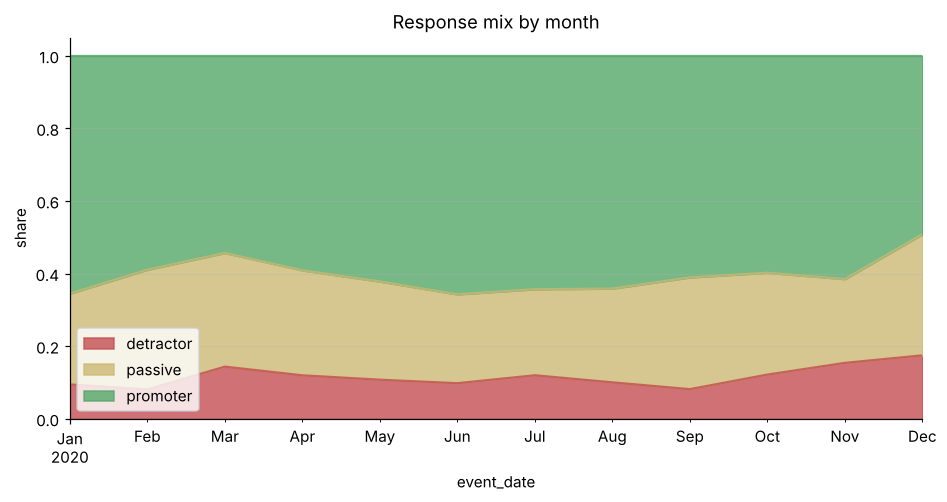

In [3]:
mix = pd.crosstab(n.event_date.dt.to_period("M"), n.group, normalize="index")
mix.index = mix.index.to_timestamp()
mix[["detractor", "passive", "promoter"]].plot.area(color=["#C44E52", "#CCB974", "#55A868"], alpha=0.8)
plt.title("Response mix by month"); plt.ylabel("share"); plt.legend(loc="lower left"); plt.show()

**How to read it:** a month-to-month move is meaningful only when it lies outside the overlapping confidence bands. Wide intervals in low-response months argue for reporting a **rolling quarterly NPS** to leadership, and for watching the detractor share, which can rise even while NPS looks flat. In this data, only **December 2020** (NPS ≈ 32, CI ≈ 18-45) is clearly below the overall level of ≈ 50, and it rests on a small sample. That is worth investigating, but not yet a trend.